# Size Spacecraft

This example estimates what a spacecraft needs to keep its orbit for its life, and how that changes a trade of altitudes. Drag from the thermosphere decays low orbits: a spacecraft must either carry propellant to hold its altitude, or fly high enough to outlast its life without it. Above some altitude, the opposite problem appears: its orbit lasts too long after its life ends, and it must spend velocity to come down within a disposal rule (25 years, by the guideline of the Inter-Agency Space Debris Coordination Committee and ISO 24113).

The example covers, in turn: the density of the thermosphere and the solar activity that drives it; the lifetimes of orbits by altitude and ballistic coefficient; the velocity budget of an orbit over a life, and its propellant; sizing a notional spacecraft from its payload and a catalog spacecraft from its own resources; and a trade study in which these give altitude a cost.

The values of the notional spacecraft below (its payload's fractions of the dry mass and power, its drag area, and its specific impulse) are assumptions for illustration, not sourced values: TAT-C gives no defaults for them, so a study states its own.

In [1]:
from datetime import datetime, timedelta, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tatc import utils
from tatc.constants import EARTH_MEAN_RADIUS

start = datetime(2027, 1, 1, tzinfo=timezone.utc)
BLUE, ORANGE, AQUA, GRAY, INK = "#257de0", "#f47230", "#00b894", "#8a8984", "#191919"
# sequential blues (light to dark) for the ordered levels of solar activity
LEVELS = {"low": "#84b9f3", "moderate": "#257de0", "high": "#0f4a96"}
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e0",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
    }
)

## The density of the thermosphere

`utils.compute_atmospheric_density` gives the density of the thermosphere from 100 to 1500 km: the mean of the NRLMSIS 2.1 empirical model over the sphere, local times, and seasons, which an orbit averages over its revolutions, from a table bundled with TAT-C. The density depends strongly on the Sun's activity (its ultraviolet output, measured by the F10.7 index, and geomagnetic storms, by Ap), so the table holds the three long-term reference levels of the European space environment standard (ECSS-E-ST-10-04C): low (F10.7 = 65), moderate (140), and high (250). At 400 km, the density at high activity is about 24 times that at low activity.

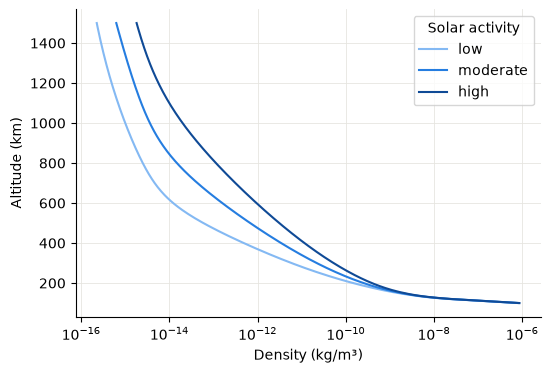

In [2]:
altitudes = np.arange(100e3, 1500e3 + 1, 5e3)
fig, ax = plt.subplots(figsize=(6, 4))
for level, color in LEVELS.items():
    ax.plot(
        utils.compute_atmospheric_density(altitudes, level),
        altitudes / 1e3,
        color=color,
        label=level,
    )
ax.set_xscale("log")
ax.set_xlabel("Density (kg/m³)")
ax.set_ylabel("Altitude (km)")
ax.legend(title="Solar activity")
plt.show()

Over a mission, the activity follows the roughly 11-year solar cycle. A `utils.SolarCycle` varies the activity as a cosine from low at its minima to high halfway between them; by default its minimum is that of December 2019, which began solar cycle 25, so the activity peaks in mid-2025 and falls to the next minimum in late 2030. Real cycles differ in length and strength, so the cycle is a mean for predictions over years, not a forecast.

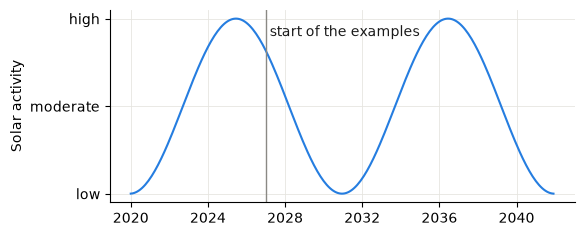

In [3]:
cycle = utils.SolarCycle()
years = pd.date_range("2019-12-15", "2041-12-15", freq="MS", tz="UTC")
fig, ax = plt.subplots(figsize=(6, 2.5))
ax.plot(years, cycle.get_activity(years), color=BLUE)
ax.axvline(start, color=GRAY, linewidth=1)
ax.annotate(" start of the examples", (start, 0.9), color=INK)
ax.set_yticks([0, 0.5, 1], ["low", "moderate", "high"])
ax.set_ylabel("Solar activity")
plt.show()

## Orbit lifetimes

Drag shrinks an orbit at a rate set by the density and by the spacecraft's ballistic coefficient: its mass over its drag coefficient times its drag area (in kg/m²). A dense spacecraft with a small cross-section (a high ballistic coefficient) decays slowly; a light one with large solar arrays decays fast. Small satellites are typically 20 to 100 kg/m².

`utils.compute_orbit_lifetime` integrates the decay, averaged over revolutions, until the perigee falls to 100 km, where a spacecraft reenters within days. The lifetimes below, at moderate activity, grow about fivefold for each 100 km of altitude from 400 to 700 km, and in proportion to the ballistic coefficient.

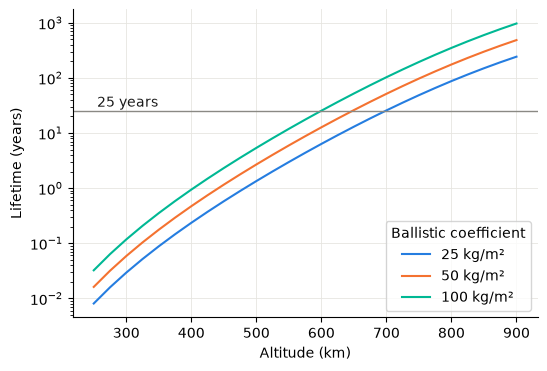

In [4]:
heights = np.arange(250e3, 900e3 + 1, 25e3)
coefficients = {25: BLUE, 50: ORANGE, 100: AQUA}
fig, ax = plt.subplots(figsize=(6, 4))
for coefficient, color in coefficients.items():
    lifetimes = [
        utils.compute_orbit_lifetime(
            EARTH_MEAN_RADIUS + h, 0, 97, coefficient, horizon=1000
        )
        for h in heights
    ]
    ax.plot(heights / 1e3, lifetimes, color=color, label=f"{coefficient} kg/m²")
ax.axhline(25, color=GRAY, linewidth=1)
ax.annotate("25 years", (255, 30), color=INK)
ax.set_yscale("log")
ax.set_xlabel("Altitude (km)")
ax.set_ylabel("Lifetime (years)")
ax.legend(title="Ballistic coefficient")
plt.show()

The solar activity matters as much as the altitude. At 500 km, a spacecraft of 50 kg/m² lasts decades at low activity but months at high activity. Under the solar cycle, its lifetime depends on when it starts: about 8 months from the maximum of 2025, but about 5 years from the minimum of 2030, as it rides out the low activity before the next maximum.

In [5]:
rows = []
for h in (400e3, 500e3, 600e3):
    row = {"altitude (km)": h / 1e3}
    for level in LEVELS:
        row[f"{level} (years)"] = utils.compute_orbit_lifetime(
            EARTH_MEAN_RADIUS + h, 0, 97, 50, activity=level
        )
    for year in (2025, 2027, 2030):
        row[f"cycle from {year} (years)"] = utils.compute_orbit_lifetime(
            EARTH_MEAN_RADIUS + h,
            0,
            97,
            50,
            activity=cycle,
            start=datetime(year, 1, 1, tzinfo=timezone.utc),
        )
    rows.append(row)
pd.DataFrame(rows).round(1)

,altitude (km),low (years),moderate (years),high (years),cycle from 2025 (years),cycle from 2027 (years),cycle from 2030 (years)
0,400.0,2.5,0.5,0.2,0.2,0.3,2.2
1,500.0,24.3,2.7,0.7,0.7,2.2,4.9
2,600.0,153.4,12.7,2.6,7.1,9.7,7.2


An eccentric orbit decays mostly at its perigee, where the air is densest: drag there lowers its apogee while its perigee falls slowly, so the orbit circularizes before it reenters (`utils.compute_orbit_decay` gives the decay over time). This is why disposal lowers a spacecraft's perigee rather than its whole orbit.

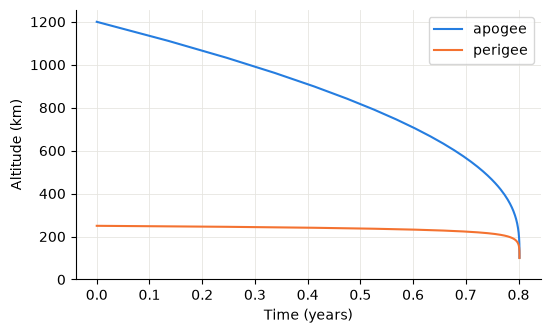

In [6]:
a = EARTH_MEAN_RADIUS + (250e3 + 1200e3) / 2
decay = utils.compute_orbit_decay(
    a, (1200e3 - 250e3) / (2 * a), 97, 50, activity="moderate"
)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(decay.time, decay.apogee_altitude / 1e3, color=BLUE, label="apogee")
ax.plot(decay.time, decay.perigee_altitude / 1e3, color=ORANGE, label="perigee")
ax.set_xlabel("Time (years)")
ax.set_ylabel("Altitude (km)")
ax.set_ylim(0, None)
ax.legend()
plt.show()

## Velocity budgets

`sizing.compute_delta_v_budget` gives the velocity a spacecraft in a near-circular orbit spends over its life: to raise its orbit from where a launch injects it (a Hohmann transfer), to hold its altitude against drag, to dispose of it at the end of its life, for other maneuvers (such as avoiding collisions), and a margin. Its disposal follows a `sizing.DisposalRule`: by default, it needs no velocity if its orbit comes down within 25 years of the end of its life, and otherwise lowers its perigee to the highest altitude from which drag brings it down within the limit (or to a given perigee, for a controlled reentry).

For a 5-year life starting in 2027 under the solar cycle, at 50 kg/m², holding the orbit against drag dominates the budget up to 650 km, where the budget is smallest (about 5 m/s), and disposal dominates above it: from 750 km, the orbit would outlast the 25-year limit after the life ends.

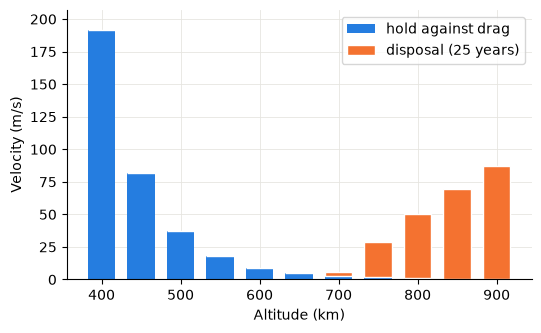

In [7]:
from tatc.schemas import CircularOrbit
from tatc.sizing import compute_delta_v_budget

budgets = pd.DataFrame(
    [
        {"altitude (km)": h / 1e3}
        | compute_delta_v_budget(
            CircularOrbit(altitude=h, inclination=97, epoch=start),
            50,
            5,
            activity=cycle,
        ).model_dump()
        for h in np.arange(400e3, 900e3 + 1, 50e3)
    ]
)
fig, ax = plt.subplots(figsize=(6, 3.5))
width = 35
ax.bar(
    budgets["altitude (km)"],
    budgets["drag"],
    width,
    color=BLUE,
    label="hold against drag",
)
ax.bar(
    budgets["altitude (km)"],
    budgets["disposal"],
    width,
    bottom=budgets["drag"],
    color=ORANGE,
    label="disposal (25 years)",
    edgecolor="white",
    linewidth=1,
)
ax.set_ylim(0, 1.08 * budgets["total"].max())
ax.set_xlabel("Altitude (km)")
ax.set_ylabel("Velocity (m/s)")
ax.legend()
plt.show()

The rocket equation (`sizing.compute_propellant_mass`) turns a budget into propellant: a hydrazine thruster's specific impulse of about 220 s needs about 2.3% of the dry mass for each 50 m/s.

In [8]:
from tatc.sizing import compute_propellant_mass

budgets["propellant per 100 kg dry (kg)"] = [
    compute_propellant_mass(100, v, 220) for v in budgets["total"]
]
budgets.round(1)

,altitude (km),raising,drag,disposal,other,margin,total,propellant per 100 kg dry (kg)
0,400.0,0.0,191.6,0.0,0.0,0.0,191.6,9.3
1,450.0,0.0,82.0,0.0,0.0,0.0,82.0,3.9
2,500.0,0.0,37.3,0.0,0.0,0.0,37.3,1.7
3,550.0,0.0,17.9,0.0,0.0,0.0,17.9,0.8
4,600.0,0.0,9.1,0.0,0.0,0.0,9.1,0.4
5,650.0,0.0,4.8,0.0,0.0,0.0,4.8,0.2
6,700.0,0.0,2.7,3.3,0.0,0.0,6.0,0.3
7,750.0,0.0,1.6,27.4,0.0,0.0,29.0,1.4
8,800.0,0.0,1.0,48.9,0.0,0.0,49.9,2.3
9,850.0,0.0,0.7,68.6,0.0,0.0,69.3,3.3


## Sizing spacecraft

`sizing.size_spacecraft` sizes a spacecraft for its orbit and life. Each value comes from the spacecraft's own resources (`schemas.SpacecraftResources`, as catalog spacecraft give) if given, or else from a `sizing.SpacecraftSizing` of the study's assumptions. A notional spacecraft's dry mass and power can be sized from its payload's, by the fractions of them the payload takes.

The notional spacecraft here carries a 40 kg, 60 W imager, assumed to be a quarter of its dry mass and 40% of its power, with a mean drag area of 1 m² and a hydrazine thruster (220 s), for a 5-year life. Its ballistic coefficient is about 73 kg/m². At 400 km it needs about 130 m/s (10 kg of propellant); at 600 km, about 6 m/s; at 800 km, about 60 m/s, mostly for its disposal.

In [9]:
from tatc.schemas import Instrument, InstrumentResources, Satellite
from tatc.sizing import SpacecraftSizing, size_spacecraft

imager = Instrument(
    name="imager", field_of_regard=30, resources=InstrumentResources(mass=40, power=60)
)
sizing = SpacecraftSizing(
    payload_mass_fraction=0.25,
    payload_power_fraction=0.4,
    design_life=5,
    drag_area=1.0,
    specific_impulse=220,
    activity=cycle,
)


def describe(sized):
    """The values of a sized spacecraft."""
    return {
        "dry mass (kg)": sized.resources.dry_mass,
        "power (W)": sized.resources.power,
        "ballistic coefficient (kg/m²)": sized.ballistic_coefficient,
        "lifetime without propulsion (years)": sized.lifetime,
        "delta-v (m/s)": np.nan if sized.budget is None else sized.budget.total,
        "propellant (kg)": sized.propellant_mass,
        "launch mass (kg)": sized.resources.launch_mass,
        "violations": ", ".join(sized.violations) or "none",
    }


notional = {}
for h in (400e3, 500e3, 600e3, 700e3, 800e3):
    satellite = Satellite(
        name="notional",
        orbit=CircularOrbit(altitude=h, inclination=97, epoch=start),
        instruments=[imager],
    )
    notional[f"{h / 1e3:.0f} km"] = describe(size_spacecraft(satellite, sizing))
pd.DataFrame(notional).T.round(1)

,dry mass (kg),power (W),ballistic coefficient (kg/m²),lifetime without propulsion (years),delta-v (m/s),propellant (kg),launch mass (kg),violations
400 km,160.0,150.0,72.727273,0.382062,131.748282,10.075102,170.075102,none
500 km,160.0,150.0,72.727273,6.714568,25.667123,1.914872,161.914872,none
600 km,160.0,150.0,72.727273,11.119698,6.244535,0.463773,160.463773,none
700 km,160.0,150.0,72.727273,41.514373,20.642561,1.538224,161.538224,none
800 km,160.0,150.0,72.727273,118.5535,62.159048,4.676837,164.676837,none


Without propulsion, the same spacecraft has an altitude window, here from 500 to 650 km: below it, its orbit decays within its life (`decay`); above it, its orbit outlasts the disposal rule after its life (`disposal`).

In [10]:
drifting = sizing.model_copy(update={"specific_impulse": None})
window = {}
for h in np.arange(450e3, 750e3 + 1, 50e3):
    satellite = Satellite(
        name="notional",
        orbit=CircularOrbit(altitude=h, inclination=97, epoch=start),
        instruments=[imager],
    )
    sized = size_spacecraft(satellite, drifting)
    window[f"{h / 1e3:.0f} km"] = {
        "lifetime (years)": sized.lifetime,
        "violations": ", ".join(sized.violations) or "none",
    }
pd.DataFrame(window).T.round(1)

,lifetime (years),violations
450 km,1.025011,decay
500 km,6.714568,none
550 km,8.931487,none
600 km,11.119698,none
650 km,21.490075,none
700 km,41.514373,disposal
750 km,66.633374,disposal


A catalog spacecraft brings its own resources. Landsat 8 (from the system catalog) gives a launch mass of 2780 kg and a dry mass of 1512 kg, so its sizing checks the propellant its budget needs against the difference of the two; its drag area is not in the catalog, so it is assumed here (15 m²). In its orbit (about 710 km above the mean radius), holding the orbit for its 5-year design life takes only about 7 m/s.

In [11]:
from tatc.catalog import get_system

landsat_8 = get_system("landsat").build(epoch=start, payload=False)[0]
sized = size_spacecraft(
    landsat_8, SpacecraftSizing(drag_area=15.0, specific_impulse=220, activity=cycle)
)
pd.Series(
    describe(sized)
    | {
        "altitude (km)": landsat_8.orbit.get_semimajor_axis() / 1e3
        - EARTH_MEAN_RADIUS / 1e3
    }
).to_frame(landsat_8.name)

C:\Users\pgrogan1\AppData\Local\Temp\ipykernel_48512\3626807910.py:3: UserWarning: landsat:plane is partial, not validated: test_sets: 2.0 fails the limit of 3
  landsat_8 = get_system("landsat").build(epoch=start, payload=False)[0]


,Landsat 8
dry mass (kg),1512.0
power (W),4300.0
ballistic coefficient (kg/m²),45.818182
lifetime without propulsion (years),30.490044
delta-v (m/s),6.929062
propellant (kg),4.863853
launch mass (kg),2780.0
violations,none
altitude (km),709.66


## Altitude in a trade study

In a trade study, a `tradespace.MissionPlan` with a `sizing` sizes the satellites of each design (see the trade space tutorial for studies). Lower orbits need more propellant, so heavier satellites: fewer of them fit a launch limited in mass, and launches priced by mass cost more. Designs whose satellites violate their sizing are infeasible, and the evaluations record the sizing's columns (`dry mass`, `propellant mass`, `launch mass`, `delta-v`, `orbit lifetime`, and `power margin`).

The study below varies the altitude of a sun-synchronous Walker constellation of two planes of two satellites, with a 5-year design life and launches of up to 360 kg, each costing 2 million dollars plus 10 thousand dollars per kg, and compares a plan that sizes its satellites with one that assumes every satellite weighs 160 kg, the dry mass of the sized satellites.

In [12]:
from tatc.generation import generate_points_fibonacci_lattice
from tatc.tradespace import (
    CostModel,
    DeploymentSchedule,
    DesignSpace,
    LaunchCost,
    MissionPlan,
    Observations,
    ObservationStudy,
    Real,
    SatelliteCost,
    Targets,
    Uncertain,
    build_constellation,
    walker_space,
)

space = DesignSpace(
    altitude=Real(300e3, 700e3, step=50e3),
    layout=walker_space(inclination=97, planes=2, per_plane=2, relative_spacing=0),
    points_seed=Uncertain.seed(),
)


def build(d):
    return build_constellation(d.layout, imager, epoch=start, altitude=d.altitude)


def metrics(observations):
    return {"observations": float(len(observations))}


schedule = DeploymentSchedule(years=5, design_life=5, launch_mass_capacity=360)
costs = CostModel(
    SatelliteCost(development=10, first_unit=2),
    launch=LaunchCost(per_launch=2, per_kg=0.01),
)
observations = Observations(
    Targets(
        generate_points_fibonacci_lattice, count=50, rotate=True, seed="points_seed"
    ),
    start,
    timedelta(hours=6),
)
plans = {
    "sized": MissionPlan(schedule, costs, sizing=sizing),
    "fixed 160 kg": MissionPlan(schedule, costs, masses=160.0),
}
results = {
    name: ObservationStudy(space, build, observations, metrics, plan=plan).run()
    for name, plan in plans.items()
}
sized_results = results["sized"].assign(altitude=lambda r: r.altitude / 1e3)
sized_results[
    ["altitude", "launch mass", "propellant mass", "delta-v", "cost launch", "cost"]
].round(1)

,altitude,launch mass,propellant mass,delta-v,cost launch,cost
0,300.0,246.5,86.5,932.5,17.9,35.9
1,350.0,186.7,26.7,332.5,15.5,33.5
2,400.0,170.1,10.1,131.7,10.8,28.8
3,450.0,164.2,4.2,56.4,10.6,28.6
4,500.0,161.9,1.9,25.7,10.5,28.5
5,550.0,160.9,0.9,12.3,10.4,28.4
6,600.0,160.5,0.5,6.2,10.4,28.4
7,650.0,160.2,0.2,3.3,10.4,28.4
8,700.0,161.5,1.5,20.6,10.5,28.5


With fixed masses, every altitude costs the same. Sized, the lowest orbits cost more: their satellites need more propellant, and from 350 km down they no longer fit two to a launch, which doubles the number of launches.

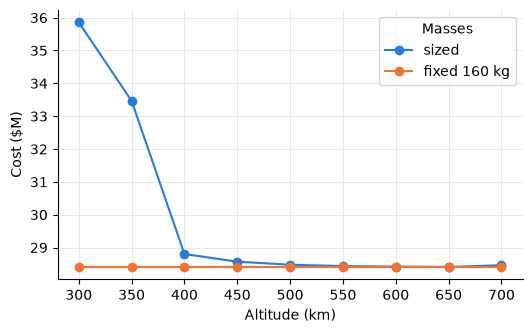

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for (name, result), color in zip(results.items(), (BLUE, ORANGE)):
    ax.plot(result.altitude / 1e3, result.cost, color=color, marker="o", label=name)
ax.set_xlabel("Altitude (km)")
ax.set_ylabel("Cost ($M)")
ax.legend(title="Masses")
plt.show()